In [2]:
!pip install python-docx

In [3]:
import os
import json
from docx import Document
from docx.shared import Pt

In [4]:
base_path = "AI-COS_Dataset"

document_path = os.path.join(base_path,"documents")
metadata_path = os.path.join(base_path,"metadata")

os.makedirs(document_path,exist_ok=True)
os.makedirs(metadata_path,exist_ok=True)

print("Folders created successfully")

Folders created successfully


In [5]:
remote_work = {
    "document_id":"HR-001",
    "title":"Remote Work Policy",
    "department":"Human Resources",
    "document_type":"Policy",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Employee",
            "type":"Permission",
            "action":"Remote Work",
            "condition":"Manager Approval",
            "limit":"3 days per week"
        }
    ],

    "entities":[
        "Employee",
        "Manager",
        "Remote Work",
        "Human Resources"
    ],

    "depends_on":[
        "HR-003",
        "HR-002",
        "IT-001"
    ],

    "affected_documents":[
        "HR-003",
        "HR-002",
        "IT-001"
    ],

    "conflicts_with":[],

    "severity":"Medium"
}

In [6]:
remote_work_text = """
REMOTE WORK POLICY

Document ID: HR-001
Department: Human Resources
Version: 1.0
Effective Date: 1 January 2026

1. Purpose

The purpose of this policy is to establish guidelines for employees who perform their work remotely.

2. Scope

This policy applies to all eligible employees of the organization.

3. Remote Work Eligibility

Eligible employees may work remotely for up to three days per week.

4. Approval

Employees must obtain approval from their reporting manager before working remotely.

5. Responsibilities

Employees working remotely are responsible for maintaining their productivity, availability, and compliance with organizational policies.

Managers are responsible for approving remote work requests and ensuring that team operations are not affected.

6. Information Security

Employees working remotely must follow all organizational information security requirements and protect company information from unauthorized access.

7. Exceptions

Exceptions to this policy may be granted by the Human Resources department based on operational requirements.

8. Effective Date

This policy is effective from 1 January 2026.
"""

In [7]:
doc = Document()

style = doc.styles["Normal"]
style.font.name = "Arial"
style.font.size = Pt(11)

for line in remote_work_text.strip().split("\n"):
    if line.strip():
        paragraph = doc.add_paragraph(line.strip())
        paragraph.paragraph_format.space_after = Pt(6)

file_name = "HR_001_Remote_Work_Policy.docx"

file_path = os.path.join(document_path,file_name)

doc.save(file_path)

print("Document created:")
print(file_path)

Document created:
AI-COS_Dataset\documents\HR_001_Remote_Work_Policy.docx


In [8]:
metadata_file = os.path.join(metadata_path,"HR_001.json")

with open(metadata_file,"w",encoding="utf-8") as f:
    json.dump(remote_work,f,indent=4)

print("Metadata saved:")
print(metadata_file)

Metadata saved:
AI-COS_Dataset\metadata\HR_001.json


In [9]:
with open(metadata_file,"r",encoding="utf-8") as f:
    data = json.load(f)

print(json.dumps(data,indent=4))

{
    "document_id": "HR-001",
    "title": "Remote Work Policy",
    "department": "Human Resources",
    "document_type": "Policy",
    "version": "1.0",
    "effective_date": "2026-01-01",
    "rules": [
        {
            "actor": "Employee",
            "type": "Permission",
            "action": "Remote Work",
            "condition": "Manager Approval",
            "limit": "3 days per week"
        }
    ],
    "entities": [
        "Employee",
        "Manager",
        "Remote Work",
        "Human Resources"
    ],
    "depends_on": [
        "HR-003",
        "HR-002",
        "IT-001"
    ],
    "affected_documents": [
        "HR-003",
        "HR-002",
        "IT-001"
    ],
    "conflicts_with": [],
    "severity": "Medium"
}


In [10]:
def create_document(data,text):
    document_id = data["document_id"]

    safe_title = data["title"].replace(" ","_")

    docx_name = f"{document_id}_{safe_title}.docx"
    json_name = f"{document_id}.json"

    docx_path = os.path.join(document_path,docx_name)
    json_path = os.path.join(metadata_path,json_name)

    doc = Document()

    style = doc.styles["Normal"]
    style.font.name = "Arial"
    style.font.size = Pt(11)

    for line in text.strip().split("\n"):
        if line.strip():
            paragraph = doc.add_paragraph(line.strip())
            paragraph.paragraph_format.space_after = Pt(6)

    doc.save(docx_path)

    with open(json_path,"w",encoding="utf-8") as f:
        json.dump(data,f,indent=4)

    print(f"Created: {docx_name}")
    print(f"Metadata: {json_name}")

In [11]:
attendance_policy = {
    "document_id":"HR-002",
    "title":"Attendance Policy",
    "department":"Human Resources",
    "document_type":"Policy",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Employee",
            "type":"Obligation",
            "action":"Maintain Attendance",
            "condition":"Working Days",
            "limit":"Required attendance according to approved work arrangement"
        }
    ],

    "entities":[
        "Employee",
        "Attendance",
        "Working Days",
        "Remote Work"
    ],

    "depends_on":[
        "HR-001",
        "HR-003"
    ],

    "affected_documents":[],

    "conflicts_with":[],

    "severity":"Medium"
}

In [12]:
attendance_text = """
ATTENDANCE POLICY

Document ID: HR-002
Department: Human Resources
Version: 1.0
Effective Date: 1 January 2026

1. Purpose

This policy establishes the attendance requirements for employees.

2. Scope

This policy applies to all employees of the organization.

3. Working Hours

Employees are expected to follow their assigned working hours and remain available during scheduled working periods.

4. Attendance

Employees must maintain attendance according to their approved work arrangement.

5. Remote Employees

Employees approved for remote work must remain available during their scheduled working hours and comply with the organization's remote work policy.

6. Manager Responsibility

Managers are responsible for monitoring attendance and ensuring that employees comply with approved work arrangements.

7. Exceptions

Exceptions may be granted by Human Resources based on operational requirements.

8. Effective Date

This policy is effective from 1 January 2026.
"""

In [13]:
create_document(attendance_policy,attendance_text)

Created: HR-002_Attendance_Policy.docx
Metadata: HR-002.json


In [14]:
remote_work["depends_on"] = []

remote_work["affected_documents"] = [
    "HR-002",
    "HR-003",
    "IT-001"
]

with open(metadata_file,"w",encoding="utf-8") as f:
    json.dump(remote_work,f,indent=4)

print("HR-001 metadata updated")

HR-001 metadata updated


In [15]:
employee_handbook = {
    "document_id":"HR-003",
    "title":"Employee Handbook",
    "department":"Human Resources",
    "document_type":"Handbook",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Employee",
            "type":"Obligation",
            "action":"Follow Organizational Policies",
            "condition":"During Employment",
            "limit":"All applicable policies"
        }
    ],

    "entities":[
        "Employee",
        "Manager",
        "Human Resources",
        "Remote Work",
        "Attendance",
        "Leave",
        "Working Hours"
    ],

    "depends_on":[
        "HR-001",
        "HR-002"
    ],

    "affected_documents":[
        "HR-004",
        "HR-005"
    ],

    "conflicts_with":[],

    "severity":"High"
}

In [16]:
employee_handbook_text = """
EMPLOYEE HANDBOOK

Document ID: HR-003
Department: Human Resources
Version: 1.0
Effective Date: 1 January 2026

1. Introduction

This handbook provides employees with general information about organizational policies, workplace expectations, and employee responsibilities.

2. Working Arrangements

Employees must follow their approved working arrangements. Remote work is permitted according to the Remote Work Policy and requires the necessary managerial approval.

3. Attendance

Employees must comply with the Attendance Policy and remain available during their scheduled working hours.

4. Leave

Employees may request leave according to the organization's Leave Policy. Leave requests must follow the applicable approval and notification requirements.

5. Working Hours

Employees are expected to follow the Working Hours Policy applicable to their role and department.

6. Information Security

Employees must comply with organizational information security requirements when accessing company systems or information.

7. Employee Responsibilities

Employees are responsible for understanding and following organizational policies that apply to their role.

8. Manager Responsibilities

Managers are responsible for communicating applicable policies to their teams and ensuring compliance.

9. Effective Date

This handbook is effective from 1 January 2026.
"""

In [17]:
create_document(employee_handbook,employee_handbook_text)

Created: HR-003_Employee_Handbook.docx
Metadata: HR-003.json


In [18]:
leave_policy = {
    "document_id":"HR-004",
    "title":"Leave Policy",
    "department":"Human Resources",
    "document_type":"Policy",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Employee",
            "type":"Permission",
            "action":"Request Leave",
            "condition":"According to Leave Rules",
            "limit":"Subject to available leave balance"
        },
        {
            "actor":"Employee",
            "type":"Obligation",
            "action":"Submit Leave Request",
            "condition":"Planned Leave",
            "limit":"At least 7 days before leave"
        }
    ],

    "entities":[
        "Employee",
        "Manager",
        "Leave",
        "Leave Balance",
        "Human Resources",
        "Payroll"
    ],

    "depends_on":[
        "HR-002",
        "HR-003"
    ],

    "affected_documents":[
        "HR-003",
        "HR-006"
    ],

    "conflicts_with":[],

    "severity":"Medium"
}

In [19]:
leave_policy_text = """
LEAVE POLICY

Document ID: HR-004
Department: Human Resources
Version: 1.0
Effective Date: 1 January 2026

1. Purpose

This policy defines the procedures and requirements for requesting and approving employee leave.

2. Scope

This policy applies to all employees of the organization.

3. Leave Eligibility

Employees may request leave according to their available leave balance and applicable organizational rules.

4. Leave Request

Employees must submit planned leave requests at least seven days before the intended leave date.

5. Manager Approval

Leave requests must be reviewed and approved by the employee's reporting manager.

6. Emergency Leave

Emergency leave may be submitted with shorter notice when circumstances prevent advance submission.

7. Attendance Records

Approved leave must be reflected in employee attendance records.

8. Payroll

Approved leave information may be used by the Payroll department for applicable salary and leave calculations.

9. Effective Date

This policy is effective from 1 January 2026.
"""

In [20]:
create_document(leave_policy,leave_policy_text)

Created: HR-004_Leave_Policy.docx
Metadata: HR-004.json


In [21]:
working_hours = {
    "document_id":"HR-005",
    "title":"Working Hours Policy",
    "department":"Human Resources",
    "document_type":"Policy",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Employee",
            "type":"Obligation",
            "action":"Work During Scheduled Hours",
            "condition":"Assigned Working Days",
            "limit":"9:00 AM to 6:00 PM"
        }
    ],

    "entities":[
        "Employee",
        "Working Hours",
        "Attendance",
        "Remote Work",
        "Manager"
    ],

    "depends_on":[
        "HR-001",
        "HR-002",
        "HR-003"
    ],

    "affected_documents":[
        "HR-002",
        "HR-003"
    ],

    "conflicts_with":[],

    "severity":"Medium"
}

In [22]:
working_hours_text = """
WORKING HOURS POLICY

Document ID: HR-005
Department: Human Resources
Version: 1.0
Effective Date: 1 January 2026

1. Purpose

This policy defines standard working hours and employee availability requirements.

2. Standard Working Hours

The standard working hours for employees are from 9:00 AM to 6:00 PM on assigned working days.

3. Employee Availability

Employees are expected to remain available during their scheduled working hours.

4. Remote Employees

Employees working remotely must follow the same scheduled working hours unless an alternative arrangement has been formally approved.

5. Attendance

Employee attendance must be recorded according to the Attendance Policy.

6. Exceptions

Managers may approve alternative working arrangements when required by operational circumstances.

7. Responsibilities

Employees are responsible for following their assigned working schedules.

Managers are responsible for communicating approved schedule changes.

8. Effective Date

This policy is effective from 1 January 2026.
"""

In [23]:
create_document(working_hours,working_hours_text)

Created: HR-005_Working_Hours_Policy.docx
Metadata: HR-005.json


In [24]:
payroll_policy = {
    "document_id":"HR-006",
    "title":"Payroll Policy",
    "department":"Human Resources",
    "document_type":"Policy",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Payroll Department",
            "type":"Obligation",
            "action":"Process Salary",
            "condition":"Monthly Payroll Cycle",
            "limit":"Based on approved attendance and leave records"
        }
    ],

    "entities":[
        "Employee",
        "Payroll",
        "Salary",
        "Attendance",
        "Leave",
        "Human Resources"
    ],

    "depends_on":[
        "HR-002",
        "HR-004"
    ],

    "affected_documents":[],

    "conflicts_with":[],

    "severity":"Medium"
}

In [25]:
payroll_policy_text = """
PAYROLL POLICY

Document ID: HR-006
Department: Human Resources
Version: 1.0
Effective Date: 1 January 2026

1. Purpose

This policy defines the procedures used to process employee payroll.

2. Payroll Cycle

Employee payroll is processed according to the organization's monthly payroll schedule.

3. Attendance Records

Payroll processing may use approved attendance records provided by the Human Resources department.

4. Leave Records

Approved employee leave records may be considered during payroll processing according to applicable organizational rules.

5. Employee Information

Payroll records must contain accurate employee identification and salary information.

6. Responsibilities

The Payroll department is responsible for processing payroll accurately and maintaining payroll records.

Human Resources is responsible for providing approved attendance and leave information.

7. Confidentiality

Payroll information must be protected against unauthorized access.

8. Effective Date

This policy is effective from 1 January 2026.
"""

In [26]:
create_document(payroll_policy,payroll_policy_text)

Created: HR-006_Payroll_Policy.docx
Metadata: HR-006.json


In [27]:
it_security = {
    "document_id":"IT-001",
    "title":"IT Security Policy",
    "department":"Information Technology",
    "document_type":"Policy",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Employee",
            "type":"Obligation",
            "action":"Protect Company Information",
            "condition":"Using Organizational Systems",
            "limit":"Follow all security requirements"
        }
    ],

    "entities":[
        "Employee",
        "Remote Work",
        "Company Information",
        "Password",
        "BYOD",
        "IT Department"
    ],

    "depends_on":[
        "HR-001"
    ],

    "affected_documents":[
        "IT-002",
        "IT-003"
    ],

    "conflicts_with":[],

    "severity":"High"
}

In [28]:
it_security_text = """
IT SECURITY POLICY

Document ID: IT-001
Department: Information Technology
Version: 1.0
Effective Date: 1 January 2026

1. Purpose

This policy establishes information security requirements for protecting organizational systems and information.

2. Scope

This policy applies to all employees and systems used to access organizational information.

3. Information Protection

Employees must protect company information from unauthorized access, modification, disclosure, or loss.

4. Remote Work

Employees accessing organizational systems remotely must follow all applicable security requirements.

5. Password Security

Employees must follow the organization's Password Policy when creating and managing passwords.

6. Personal Devices

Employees using personal devices for organizational work must comply with the BYOD Policy.

7. Incident Reporting

Security incidents must be reported to the Information Technology department according to the applicable incident response procedures.

8. Responsibilities

Employees are responsible for protecting their credentials and organizational information.

The IT department is responsible for maintaining organizational security controls.

9. Effective Date

This policy is effective from 1 January 2026.
"""

In [29]:
create_document(it_security,it_security_text)

Created: IT-001_IT_Security_Policy.docx
Metadata: IT-001.json


In [30]:
password_policy = {
    "document_id":"IT-002",
    "title":"Password Policy",
    "department":"Information Technology",
    "document_type":"Policy",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Employee",
            "type":"Obligation",
            "action":"Create Strong Password",
            "condition":"Account Creation or Password Reset",
            "limit":"Minimum 12 characters"
        },
        {
            "actor":"Employee",
            "type":"Obligation",
            "action":"Change Password",
            "condition":"Security Requirement",
            "limit":"Every 180 days"
        }
    ],

    "entities":[
        "Employee",
        "Password",
        "Account",
        "IT Department",
        "Authentication"
    ],

    "depends_on":[
        "IT-001"
    ],

    "affected_documents":[
        "IT-001",
        "IT-003"
    ],

    "conflicts_with":[],

    "severity":"High"
}

In [31]:
password_policy_text = """
PASSWORD POLICY

Document ID: IT-002
Department: Information Technology
Version: 1.0
Effective Date: 1 January 2026

1. Purpose

This policy defines requirements for creating and maintaining secure passwords.

2. Scope

This policy applies to all employees with organizational accounts.

3. Password Requirements

Employees must create passwords containing at least 12 characters.

4. Password Changes

Employees must change their organizational passwords every 180 days or whenever instructed by the IT department.

5. Password Protection

Employees must not share their passwords with other individuals.

6. Remote Access

Employees accessing organizational systems remotely must follow these password requirements.

7. Responsibilities

Employees are responsible for protecting their authentication credentials.

The IT department is responsible for enforcing password security requirements.

8. Effective Date

This policy is effective from 1 January 2026.
"""

In [32]:
create_document(password_policy,password_policy_text)

Created: IT-002_Password_Policy.docx
Metadata: IT-002.json


In [33]:
byod_policy = {
    "document_id":"IT-003",
    "title":"BYOD Policy",
    "department":"Information Technology",
    "document_type":"Policy",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Employee",
            "type":"Permission",
            "action":"Use Personal Device",
            "condition":"Authorized Organizational Work",
            "limit":"Subject to IT security requirements"
        },
        {
            "actor":"Employee",
            "type":"Obligation",
            "action":"Protect Organizational Data",
            "condition":"Using Personal Device",
            "limit":"Follow IT Security Policy"
        }
    ],

    "entities":[
        "Employee",
        "Personal Device",
        "Organizational Data",
        "Remote Work",
        "IT Security"
    ],

    "depends_on":[
        "IT-001",
        "IT-002"
    ],

    "affected_documents":[
        "IT-001"
    ],

    "conflicts_with":[],

    "severity":"High"
}

In [34]:
byod_policy_text = """
BRING YOUR OWN DEVICE POLICY

Document ID: IT-003
Department: Information Technology
Version: 1.0
Effective Date: 1 January 2026

1. Purpose

This policy defines requirements for employees who use personal devices for organizational work.

2. Scope

This policy applies to employees authorized to use personal devices for accessing organizational systems or information.

3. Authorization

Employees may use personal devices for organizational work when such use is authorized by the organization.

4. Security Requirements

Personal devices used for organizational work must comply with the organization's IT Security Policy.

5. Password Protection

Employees must use appropriate authentication controls when accessing organizational systems from personal devices.

6. Data Protection

Employees must protect organizational information stored or accessed through personal devices.

7. Remote Work

Employees working remotely may use authorized personal devices subject to applicable security requirements.

8. Responsibilities

Employees are responsible for maintaining the security of their personal devices.

The IT department is responsible for defining applicable technical security requirements.

9. Effective Date

This policy is effective from 1 January 2026.
"""

In [35]:
create_document(byod_policy,byod_policy_text)

Created: IT-003_BYOD_Policy.docx
Metadata: IT-003.json


In [36]:
expense_policy = {
    "document_id":"FIN-001",
    "title":"Employee Expense Policy",
    "department":"Finance",
    "document_type":"Policy",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Employee",
            "type":"Permission",
            "action":"Claim Business Expense",
            "condition":"Business Purpose",
            "limit":"Within approved expense limits"
        },
        {
            "actor":"Employee",
            "type":"Obligation",
            "action":"Submit Expense Claim",
            "condition":"After Business Expense",
            "limit":"Within 30 days"
        }
    ],

    "entities":[
        "Employee",
        "Expense",
        "Reimbursement",
        "Manager",
        "Finance"
    ],

    "depends_on":[],

    "affected_documents":[
        "FIN-002",
        "FIN-003"
    ],

    "conflicts_with":[],

    "severity":"Medium"
}

In [37]:
expense_policy_text = """
EMPLOYEE EXPENSE POLICY

Document ID: FIN-001
Department: Finance
Version: 1.0
Effective Date: 1 January 2026

1. Purpose

This policy defines requirements for business-related employee expenses.

2. Scope

This policy applies to employees who incur expenses on behalf of the organization.

3. Business Expenses

Employees may claim legitimate business expenses that are necessary for authorized organizational activities.

4. Expense Submission

Employees must submit expense claims within 30 days of incurring the expense.

5. Supporting Documents

Employees must provide appropriate receipts or supporting documentation for submitted expenses.

6. Approval

Expense claims must be reviewed and approved according to the organization's approval authority requirements.

7. Reimbursement

Approved expenses may be reimbursed according to the Reimbursement Policy.

8. Responsibilities

Employees are responsible for submitting accurate expense claims.

Managers and Finance personnel are responsible for reviewing claims according to their assigned authority.

9. Effective Date

This policy is effective from 1 January 2026.
"""

In [38]:
create_document(expense_policy,expense_policy_text)

Created: FIN-001_Employee_Expense_Policy.docx
Metadata: FIN-001.json


In [39]:
reimbursement_policy = {
    "document_id":"FIN-002",
    "title":"Reimbursement Policy",
    "department":"Finance",
    "document_type":"Policy",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Finance Department",
            "type":"Obligation",
            "action":"Process Approved Reimbursement",
            "condition":"Valid Approved Claim",
            "limit":"According to reimbursement rules"
        }
    ],

    "entities":[
        "Employee",
        "Expense",
        "Reimbursement",
        "Finance",
        "Manager"
    ],

    "depends_on":[
        "FIN-001",
        "FIN-003"
    ],

    "affected_documents":[
        "FIN-001"
    ],

    "conflicts_with":[],

    "severity":"Medium"
}

In [40]:
reimbursement_text = """
REIMBURSEMENT POLICY

Document ID: FIN-002
Department: Finance
Version: 1.0
Effective Date: 1 January 2026

1. Purpose

This policy defines the process for reimbursing employees for approved business expenses.

2. Eligibility

Employees may receive reimbursement for eligible business expenses approved according to organizational requirements.

3. Documentation

A valid expense claim must contain the required supporting documentation.

4. Approval

Expense claims must receive the required approval before reimbursement is processed.

5. Processing

The Finance department is responsible for processing approved reimbursement requests.

6. Reimbursement Limits

Reimbursement is subject to the applicable limits and approval authority defined by the organization.

7. Responsibilities

Employees are responsible for submitting accurate claims.

Managers are responsible for reviewing claims within their authority.

Finance is responsible for processing approved claims.

8. Effective Date

This policy is effective from 1 January 2026.
"""

In [41]:
create_document(reimbursement_policy,reimbursement_text)

Created: FIN-002_Reimbursement_Policy.docx
Metadata: FIN-002.json


In [42]:
approval_authority = {
    "document_id":"FIN-003",
    "title":"Financial Approval Authority Policy",
    "department":"Finance",
    "document_type":"Policy",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Manager",
            "type":"Permission",
            "action":"Approve Expense",
            "condition":"Expense Amount",
            "limit":"Up to INR 50000"
        },
        {
            "actor":"Finance Director",
            "type":"Permission",
            "action":"Approve Expense",
            "condition":"Expense Amount",
            "limit":"Up to INR 200000"
        }
    ],

    "entities":[
        "Manager",
        "Finance Director",
        "Expense",
        "Approval",
        "Finance"
    ],

    "depends_on":[
        "FIN-001"
    ],

    "affected_documents":[
        "FIN-002"
    ],

    "conflicts_with":[],

    "severity":"High"
}

In [43]:
approval_authority_text = """
FINANCIAL APPROVAL AUTHORITY POLICY

Document ID: FIN-003
Department: Finance
Version: 1.0
Effective Date: 1 January 2026

1. Purpose

This policy defines the financial approval authority assigned to organizational roles.

2. Manager Authority

Managers may approve employee expense claims up to INR 50,000.

3. Finance Director Authority

Finance Directors may approve employee expense claims up to INR 200,000.

4. Approval Requirements

Expense claims must be approved by an authorized person before reimbursement is processed.

5. Escalation

Expense claims exceeding the approval authority of one role must be escalated to an appropriate authorized role.

6. Responsibilities

Approvers are responsible for reviewing expense claims before providing approval.

The Finance department is responsible for maintaining approval authority records.

7. Effective Date

This policy is effective from 1 January 2026.
"""

In [44]:
create_document(approval_authority,approval_authority_text)

Created: FIN-003_Financial_Approval_Authority_Policy.docx
Metadata: FIN-003.json


In [45]:
relationships = [
    {
        "source":"HR-001",
        "target":"HR-002",
        "relationship":"AFFECTS"
    },
    {
        "source":"HR-001",
        "target":"HR-003",
        "relationship":"AFFECTS"
    },
    {
        "source":"HR-001",
        "target":"IT-001",
        "relationship":"AFFECTS"
    },
    {
        "source":"HR-002",
        "target":"HR-003",
        "relationship":"REFERENCES"
    },
    {
        "source":"HR-002",
        "target":"HR-005",
        "relationship":"INFLUENCES"
    },
    {
        "source":"HR-003",
        "target":"HR-004",
        "relationship":"REFERENCES"
    },
    {
        "source":"HR-003",
        "target":"HR-005",
        "relationship":"REFERENCES"
    },
    {
        "source":"HR-004",
        "target":"HR-006",
        "relationship":"AFFECTS"
    },
    {
        "source":"HR-005",
        "target":"HR-002",
        "relationship":"INFLUENCES"
    },
    {
        "source":"IT-001",
        "target":"IT-002",
        "relationship":"REFERENCES"
    },
    {
        "source":"IT-001",
        "target":"IT-003",
        "relationship":"REFERENCES"
    },
    {
        "source":"IT-002",
        "target":"IT-003",
        "relationship":"INFLUENCES"
    },
    {
        "source":"FIN-001",
        "target":"FIN-002",
        "relationship":"REFERENCES"
    },
    {
        "source":"FIN-001",
        "target":"FIN-003",
        "relationship":"REFERENCES"
    },
    {
        "source":"FIN-003",
        "target":"FIN-002",
        "relationship":"CONTROLS"
    }
]

relationship_file = os.path.join(base_path,"relationships.json")

with open(relationship_file,"w",encoding="utf-8") as f:
    json.dump(relationships,f,indent=4)

print("Relationship file created")

Relationship file created


In [46]:
data_protection = {
    "document_id":"IT-004",
    "title":"Data Protection Policy",
    "department":"Information Technology",
    "document_type":"Policy",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Employee",
            "type":"Obligation",
            "action":"Protect Organizational Data",
            "condition":"Accessing or Processing Company Data",
            "limit":"Prevent unauthorized access or disclosure"
        },
        {
            "actor":"Employee",
            "type":"Prohibition",
            "action":"Store Confidential Data on Unauthorized Devices",
            "condition":"Without IT Approval",
            "limit":"Not permitted"
        }
    ],

    "entities":[
        "Employee",
        "Organizational Data",
        "Confidential Data",
        "Personal Device",
        "Remote Work",
        "IT Department"
    ],

    "depends_on":[
        "IT-001",
        "IT-003"
    ],

    "affected_documents":[
        "IT-005",
        "IT-006"
    ],

    "conflicts_with":[],

    "severity":"High"
}

In [47]:
data_protection_text = """
DATA PROTECTION POLICY

Document ID: IT-004
Department: Information Technology
Version: 1.0
Effective Date: 1 January 2026

1. Purpose

This policy establishes requirements for protecting organizational information and preventing unauthorized access or disclosure.

2. Scope

This policy applies to all employees who access, process, store, or transmit organizational information.

3. Data Protection

Employees must protect organizational data from unauthorized access, modification, disclosure, or loss.

4. Confidential Information

Confidential information must only be accessed by authorized individuals with a legitimate organizational requirement.

5. Personal Devices

Employees must not store confidential organizational information on unauthorized personal devices.

6. Remote Work

Employees working remotely must ensure that organizational information is protected from unauthorized access.

7. Data Sharing

Employees must not share confidential organizational information with unauthorized individuals or external parties.

8. Security Incidents

Suspected data breaches or unauthorized disclosures must be reported according to the Incident Response Policy.

9. Access Control

Access to organizational information must follow the requirements defined in the Access Control Policy.

10. Responsibilities

Employees are responsible for protecting information they access or handle.

The IT department is responsible for maintaining appropriate technical controls.

11. Effective Date

This policy is effective from 1 January 2026.
"""

In [48]:
create_document(data_protection,data_protection_text)

Created: IT-004_Data_Protection_Policy.docx
Metadata: IT-004.json


In [49]:
incident_response = {
    "document_id":"IT-005",
    "title":"Incident Response Policy",
    "department":"Information Technology",
    "document_type":"Policy",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Employee",
            "type":"Obligation",
            "action":"Report Security Incident",
            "condition":"Suspected Security Incident",
            "limit":"Immediately"
        },
        {
            "actor":"IT Security Team",
            "type":"Obligation",
            "action":"Investigate Security Incident",
            "condition":"Reported Incident",
            "limit":"According to incident severity"
        }
    ],

    "entities":[
        "Employee",
        "Security Incident",
        "Data Breach",
        "IT Security Team",
        "Incident Response",
        "Data Protection"
    ],

    "depends_on":[
        "IT-001",
        "IT-004"
    ],

    "affected_documents":[
        "IT-004",
        "IT-006"
    ],

    "conflicts_with":[],

    "severity":"High"
}

In [50]:
incident_response_text = """
INCIDENT RESPONSE POLICY

Document ID: IT-005
Department: Information Technology
Version: 1.0
Effective Date: 1 January 2026

1. Purpose

This policy defines the procedures for identifying, reporting, investigating, and responding to information security incidents.

2. Scope

This policy applies to all employees and organizational systems.

3. Incident Reporting

Employees must immediately report suspected security incidents to the IT Security Team.

4. Data Breaches

Suspected unauthorized access, disclosure, modification, or loss of organizational information must be treated as a potential security incident.

5. Investigation

The IT Security Team is responsible for investigating reported security incidents and determining their severity.

6. Containment

Appropriate containment measures must be taken to reduce the impact of confirmed security incidents.

7. Data Protection

Incidents involving organizational information must be handled according to the Data Protection Policy.

8. Documentation

Security incidents must be documented with relevant information regarding the incident, affected systems, and actions taken.

9. Responsibilities

Employees are responsible for reporting suspected incidents.

The IT Security Team is responsible for investigation and response.

10. Effective Date

This policy is effective from 1 January 2026.
"""

In [51]:
create_document(incident_response,incident_response_text)

Created: IT-005_Incident_Response_Policy.docx
Metadata: IT-005.json


In [52]:
access_control = {
    "document_id":"IT-006",
    "title":"Access Control Policy",
    "department":"Information Technology",
    "document_type":"Policy",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Employee",
            "type":"Permission",
            "action":"Access Organizational Systems",
            "condition":"Authorized Role",
            "limit":"Only required resources"
        },
        {
            "actor":"IT Administrator",
            "type":"Obligation",
            "action":"Review User Access",
            "condition":"Periodic Review",
            "limit":"Every 90 days"
        }
    ],

    "entities":[
        "Employee",
        "IT Administrator",
        "System Access",
        "Organizational System",
        "Password",
        "Data Protection"
    ],

    "depends_on":[
        "IT-001",
        "IT-002",
        "IT-004",
        "IT-005"
    ],

    "affected_documents":[
        "IT-001",
        "IT-004",
        "IT-005"
    ],

    "conflicts_with":[],

    "severity":"High"
}

In [53]:
access_control_text = """
ACCESS CONTROL POLICY

Document ID: IT-006
Department: Information Technology
Version: 1.0
Effective Date: 1 January 2026

1. Purpose

This policy establishes requirements for controlling access to organizational systems and information.

2. Scope

This policy applies to all employees, administrators, and organizational systems.

3. Access Authorization

Employees may access organizational systems only when access has been authorized according to their organizational role.

4. Least Privilege

Users must receive only the system access required to perform their assigned responsibilities.

5. Authentication

Users must authenticate using approved organizational authentication mechanisms.

6. Access Review

IT administrators must review user access rights at least once every 90 days.

7. Access Removal

Access must be removed when an employee leaves the organization or no longer requires the associated resources.

8. Data Protection

Access to confidential organizational information must comply with the Data Protection Policy.

9. Incident Response

Unauthorized access incidents must be reported and handled according to the Incident Response Policy.

10. Responsibilities

Employees are responsible for using only authorized systems and resources.

IT administrators are responsible for managing and reviewing access rights.

11. Effective Date

This policy is effective from 1 January 2026.
"""

In [54]:
create_document(access_control,access_control_text)

Created: IT-006_Access_Control_Policy.docx
Metadata: IT-006.json


In [55]:
procurement_policy = {
    "document_id":"FIN-004",
    "title":"Procurement Policy",
    "department":"Finance",
    "document_type":"Policy",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Employee",
            "type":"Obligation",
            "action":"Obtain Procurement Approval",
            "condition":"Organizational Purchase",
            "limit":"Before purchase"
        },
        {
            "actor":"Manager",
            "type":"Permission",
            "action":"Approve Purchase",
            "condition":"Purchase Amount",
            "limit":"Up to INR 50000"
        }
    ],

    "entities":[
        "Employee",
        "Manager",
        "Purchase",
        "Procurement",
        "Finance",
        "Approval"
    ],

    "depends_on":[
        "FIN-001",
        "FIN-003"
    ],

    "affected_documents":[
        "FIN-005"
    ],

    "conflicts_with":[],

    "severity":"High"
}

In [56]:
procurement_text = """
PROCUREMENT POLICY

Document ID: FIN-004
Department: Finance
Version: 1.0
Effective Date: 1 January 2026

1. Purpose

This policy defines the procedures and approval requirements for organizational purchases.

2. Scope

This policy applies to employees and departments making purchases on behalf of the organization.

3. Purchase Authorization

Employees must obtain the required approval before making organizational purchases.

4. Manager Approval

Managers may approve purchases up to INR 50,000 within their assigned authority.

5. Higher-Value Purchases

Purchases exceeding the assigned managerial authority must be escalated to an authorized Finance representative.

6. Documentation

Purchase requests must contain appropriate information regarding the item, purpose, estimated cost, and supplier.

7. Supplier Selection

Organizational purchases must follow approved supplier and procurement procedures.

8. Expense Claims

Employees must follow the Employee Expense Policy when claiming eligible business expenses related to purchases.

9. Responsibilities

Employees are responsible for obtaining appropriate authorization.

Managers and Finance personnel are responsible for reviewing purchases within their authority.

10. Effective Date

This policy is effective from 1 January 2026.
"""

In [57]:
create_document(procurement_policy,procurement_text)

Created: FIN-004_Procurement_Policy.docx
Metadata: FIN-004.json


In [58]:
travel_policy = {
    "document_id":"FIN-005",
    "title":"Travel Expense Policy",
    "department":"Finance",
    "document_type":"Policy",
    "version":"1.0",
    "effective_date":"2026-01-01",

    "rules":[
        {
            "actor":"Employee",
            "type":"Permission",
            "action":"Claim Travel Expense",
            "condition":"Authorized Business Travel",
            "limit":"Within approved limits"
        },
        {
            "actor":"Employee",
            "type":"Obligation",
            "action":"Submit Travel Claim",
            "condition":"After Business Travel",
            "limit":"Within 30 days"
        }
    ],

    "entities":[
        "Employee",
        "Manager",
        "Travel",
        "Travel Expense",
        "Reimbursement",
        "Finance"
    ],

    "depends_on":[
        "FIN-001",
        "FIN-002",
        "FIN-003",
        "FIN-004"
    ],

    "affected_documents":[
        "FIN-001",
        "FIN-002"
    ],

    "conflicts_with":[],

    "severity":"Medium"
}

In [59]:
travel_policy_text = """
TRAVEL EXPENSE POLICY

Document ID: FIN-005
Department: Finance
Version: 1.0
Effective Date: 1 January 2026

1. Purpose

This policy defines the requirements for employee business travel and related expenses.

2. Scope

This policy applies to employees undertaking authorized business travel on behalf of the organization.

3. Travel Authorization

Employees must obtain appropriate approval before undertaking business travel.

4. Eligible Expenses

Reasonable travel expenses incurred for authorized business purposes may be claimed according to organizational limits.

5. Transportation

Transportation expenses must be supported by appropriate receipts or travel documentation.

6. Accommodation

Accommodation expenses must remain within the limits established by the organization unless an exception has been approved.

7. Expense Submission

Employees must submit travel expense claims within 30 days after completing the business trip.

8. Approval

Travel expense claims must be reviewed according to the Financial Approval Authority Policy.

9. Reimbursement

Approved travel expenses may be reimbursed according to the Reimbursement Policy.

10. Procurement

Travel-related purchases must comply with applicable procurement requirements.

11. Effective Date

This policy is effective from 1 January 2026.
"""

In [60]:
create_document(travel_policy,travel_policy_text)

Created: FIN-005_Travel_Expense_Policy.docx
Metadata: FIN-005.json


In [61]:
new_relationships = [
    {
        "source":"IT-001",
        "target":"IT-004",
        "relationship":"REFERENCES"
    },
    {
        "source":"IT-004",
        "target":"IT-005",
        "relationship":"REFERENCES"
    },
    {
        "source":"IT-004",
        "target":"IT-006",
        "relationship":"REFERENCES"
    },
    {
        "source":"IT-005",
        "target":"IT-006",
        "relationship":"INFLUENCES"
    },
    {
        "source":"IT-002",
        "target":"IT-006",
        "relationship":"CONTROLS"
    },
    {
        "source":"IT-006",
        "target":"IT-004",
        "relationship":"CONTROLS"
    },
    {
        "source":"FIN-001",
        "target":"FIN-004",
        "relationship":"REFERENCES"
    },
    {
        "source":"FIN-003",
        "target":"FIN-004",
        "relationship":"CONTROLS"
    },
    {
        "source":"FIN-004",
        "target":"FIN-005",
        "relationship":"INFLUENCES"
    },
    {
        "source":"FIN-002",
        "target":"FIN-005",
        "relationship":"REFERENCES"
    },
    {
        "source":"FIN-003",
        "target":"FIN-005",
        "relationship":"CONTROLS"
    },
    {
        "source":"FIN-001",
        "target":"FIN-005",
        "relationship":"REFERENCES"
    }
]

relationships.extend(new_relationships)

with open(relationship_file,"w",encoding="utf-8") as f:
    json.dump(relationships,f,indent=4)

print("Relationship file updated")
print("Total relationships:",len(relationships))

Relationship file updated
Total relationships: 27


In [63]:
print("Documents created:")
print(os.listdir(document_path))

print("\nMetadata files:")
print(os.listdir(metadata_path))

Documents created:
['.ipynb_checkpoints', 'FIN-001_Employee_Expense_Policy.docx', 'FIN-002_Reimbursement_Policy.docx', 'FIN-003_Financial_Approval_Authority_Policy.docx', 'FIN-004_Procurement_Policy.docx', 'FIN-005_Travel_Expense_Policy.docx', 'HR-002_Attendance_Policy.docx', 'HR-003_Employee_Handbook.docx', 'HR-004_Leave_Policy.docx', 'HR-005_Working_Hours_Policy.docx', 'HR-006_Payroll_Policy.docx', 'HR_001_Remote_Work_Policy.docx', 'IT-001_IT_Security_Policy.docx', 'IT-002_Password_Policy.docx', 'IT-003_BYOD_Policy.docx', 'IT-004_Data_Protection_Policy.docx', 'IT-005_Incident_Response_Policy.docx', 'IT-006_Access_Control_Policy.docx']

Metadata files:
['FIN-001.json', 'FIN-002.json', 'FIN-003.json', 'FIN-004.json', 'FIN-005.json', 'HR-002.json', 'HR-003.json', 'HR-004.json', 'HR-005.json', 'HR-006.json', 'HR_001.json', 'IT-001.json', 'IT-002.json', 'IT-003.json', 'IT-004.json', 'IT-005.json', 'IT-006.json']


In [64]:
scenario_path = os.path.join(base_path,"scenarios")

os.makedirs(scenario_path,exist_ok=True)

print("Scenario folder created")

Scenario folder created


In [65]:
scenario_1 = {
    "scenario_id":"SIPA-001",

    "changed_document":"HR-001",

    "change_type":"Policy Limit Change",

    "old_rule":{
        "actor":"Employee",
        "type":"Permission",
        "action":"Remote Work",
        "limit":"3 days per week"
    },

    "new_rule":{
        "actor":"Employee",
        "type":"Permission",
        "action":"Remote Work",
        "limit":"2 days per week"
    },

    "expected_affected_documents":[
        "HR-002",
        "HR-003",
        "HR-005",
        "IT-001"
    ],

    "expected_unaffected_documents":[
        "HR-004",
        "HR-006",
        "IT-002",
        "IT-003",
        "IT-004",
        "IT-005",
        "IT-006",
        "FIN-001",
        "FIN-002",
        "FIN-003",
        "FIN-004",
        "FIN-005"
    ],

    "impact_severity":"High"
}

with open(os.path.join(scenario_path,"SIPA-001.json"),"w",encoding="utf-8") as f:
    json.dump(scenario_1,f,indent=4)

In [66]:
scenario_2 = {
    "scenario_id":"SIPA-002",

    "changed_document":"IT-002",

    "change_type":"Security Requirement Change",

    "old_rule":{
        "actor":"Employee",
        "type":"Obligation",
        "action":"Create Strong Password",
        "limit":"Minimum 12 characters"
    },

    "new_rule":{
        "actor":"Employee",
        "type":"Obligation",
        "action":"Create Strong Password",
        "limit":"Minimum 16 characters"
    },

    "expected_affected_documents":[
        "IT-001",
        "IT-003",
        "IT-006"
    ],

    "expected_unaffected_documents":[
        "HR-001",
        "HR-002",
        "HR-003",
        "HR-004",
        "HR-005",
        "HR-006",
        "IT-004",
        "IT-005",
        "FIN-001",
        "FIN-002",
        "FIN-003",
        "FIN-004",
        "FIN-005"
    ],

    "impact_severity":"High"
}

with open(os.path.join(scenario_path,"SIPA-002.json"),"w",encoding="utf-8") as f:
    json.dump(scenario_2,f,indent=4)

In [67]:
scenario_3 = {
    "scenario_id":"SIPA-003",

    "changed_document":"FIN-003",

    "change_type":"Authority Threshold Change",

    "old_rule":{
        "actor":"Manager",
        "type":"Permission",
        "action":"Approve Expense",
        "limit":"Up to INR 50000"
    },

    "new_rule":{
        "actor":"Manager",
        "type":"Permission",
        "action":"Approve Expense",
        "limit":"Up to INR 100000"
    },

    "expected_affected_documents":[
        "FIN-001",
        "FIN-002",
        "FIN-004",
        "FIN-005"
    ],

    "expected_unaffected_documents":[
        "HR-001",
        "HR-002",
        "HR-003",
        "HR-004",
        "HR-005",
        "HR-006",
        "IT-001",
        "IT-002",
        "IT-003",
        "IT-004",
        "IT-005",
        "IT-006"
    ],

    "impact_severity":"High"
}

with open(os.path.join(scenario_path,"SIPA-003.json"),"w",encoding="utf-8") as f:
    json.dump(scenario_3,f,indent=4)

In [68]:
conflict_path = os.path.join(base_path,"conflicts")

os.makedirs(conflict_path,exist_ok=True)

In [69]:
conflict_1 = {
    "conflict_id":"ASCD-001",

    "document_a":"HR-001",
    "document_b":"HR-CONFLICT-001",

    "rule_a":{
        "actor":"Employee",
        "type":"Permission",
        "action":"Remote Work",
        "condition":"Eligible Employee",
        "temporal_scope":"Weekdays"
    },

    "rule_b":{
        "actor":"Employee",
        "type":"Obligation",
        "action":"Work From Office",
        "condition":"Weekdays",
        "temporal_scope":"Weekdays"
    },

    "dimensions":{
        "actor_match":True,
        "action_overlap":True,
        "temporal_overlap":True,
        "scope_overlap":True,
        "exception_present":False,
        "authority_override":False
    },

    "expected_conflict":True,

    "conflict_type":"Permission vs Obligation",

    "severity":"High"
}

with open(os.path.join(conflict_path,"ASCD-001.json"),"w",encoding="utf-8") as f:
    json.dump(conflict_1,f,indent=4)

In [70]:
conflict_2 = {
    "conflict_id":"ASCD-002",

    "document_a":"HR-001",
    "document_b":"HR-CONFLICT-002",

    "rule_a":{
        "actor":"Employee",
        "type":"Permission",
        "action":"Remote Work",
        "condition":"Eligible Employee",
        "temporal_scope":"Up to 3 days per week"
    },

    "rule_b":{
        "actor":"Employee",
        "type":"Obligation",
        "action":"Work From Office",
        "condition":"Friday",
        "temporal_scope":"Friday"
    },

    "dimensions":{
        "actor_match":True,
        "action_overlap":True,
        "temporal_overlap":False,
        "scope_overlap":True,
        "exception_present":False,
        "authority_override":False
    },

    "expected_conflict":False,

    "conflict_type":"Compatible Temporal Rules",

    "severity":"Low"
}

with open(os.path.join(conflict_path,"ASCD-002.json"),"w",encoding="utf-8") as f:
    json.dump(conflict_2,f,indent=4)

In [71]:
conflict_3 = {
    "conflict_id":"ASCD-003",

    "document_a":"FIN-003",
    "document_b":"FIN-CONFLICT-003",

    "rule_a":{
        "actor":"Manager",
        "type":"Permission",
        "action":"Approve Expense",
        "condition":"Expense Amount",
        "limit":"Up to INR 50000"
    },

    "rule_b":{
        "actor":"Manager",
        "type":"Permission",
        "action":"Approve Expense",
        "condition":"Expense Amount",
        "limit":"Up to INR 25000"
    },

    "dimensions":{
        "actor_match":True,
        "action_overlap":True,
        "temporal_overlap":True,
        "scope_overlap":True,
        "exception_present":False,
        "authority_override":False
    },

    "expected_conflict":True,

    "conflict_type":"Threshold Conflict",

    "severity":"High"
}

with open(os.path.join(conflict_path,"ASCD-003.json"),"w",encoding="utf-8") as f:
    json.dump(conflict_3,f,indent=4)

In [72]:
import os
import json

base_path = "AI-COS_Dataset"
relationship_file = os.path.join(base_path,"relationships.json")

with open(relationship_file,"r",encoding="utf-8") as f:
    relationships = json.load(f)

print("Total relationships:",len(relationships))

Total relationships: 27


In [73]:
!pip install networkx matplotlib

In [74]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for relation in relationships:
    source = relation["source"]
    target = relation["target"]
    relationship_type = relation["relationship"]

    G.add_edge(
        source,
        target,
        relationship=relationship_type
    )

print("Documents in graph:",G.number_of_nodes())
print("Relationships:",G.number_of_edges())

Documents in graph: 17
Relationships: 27


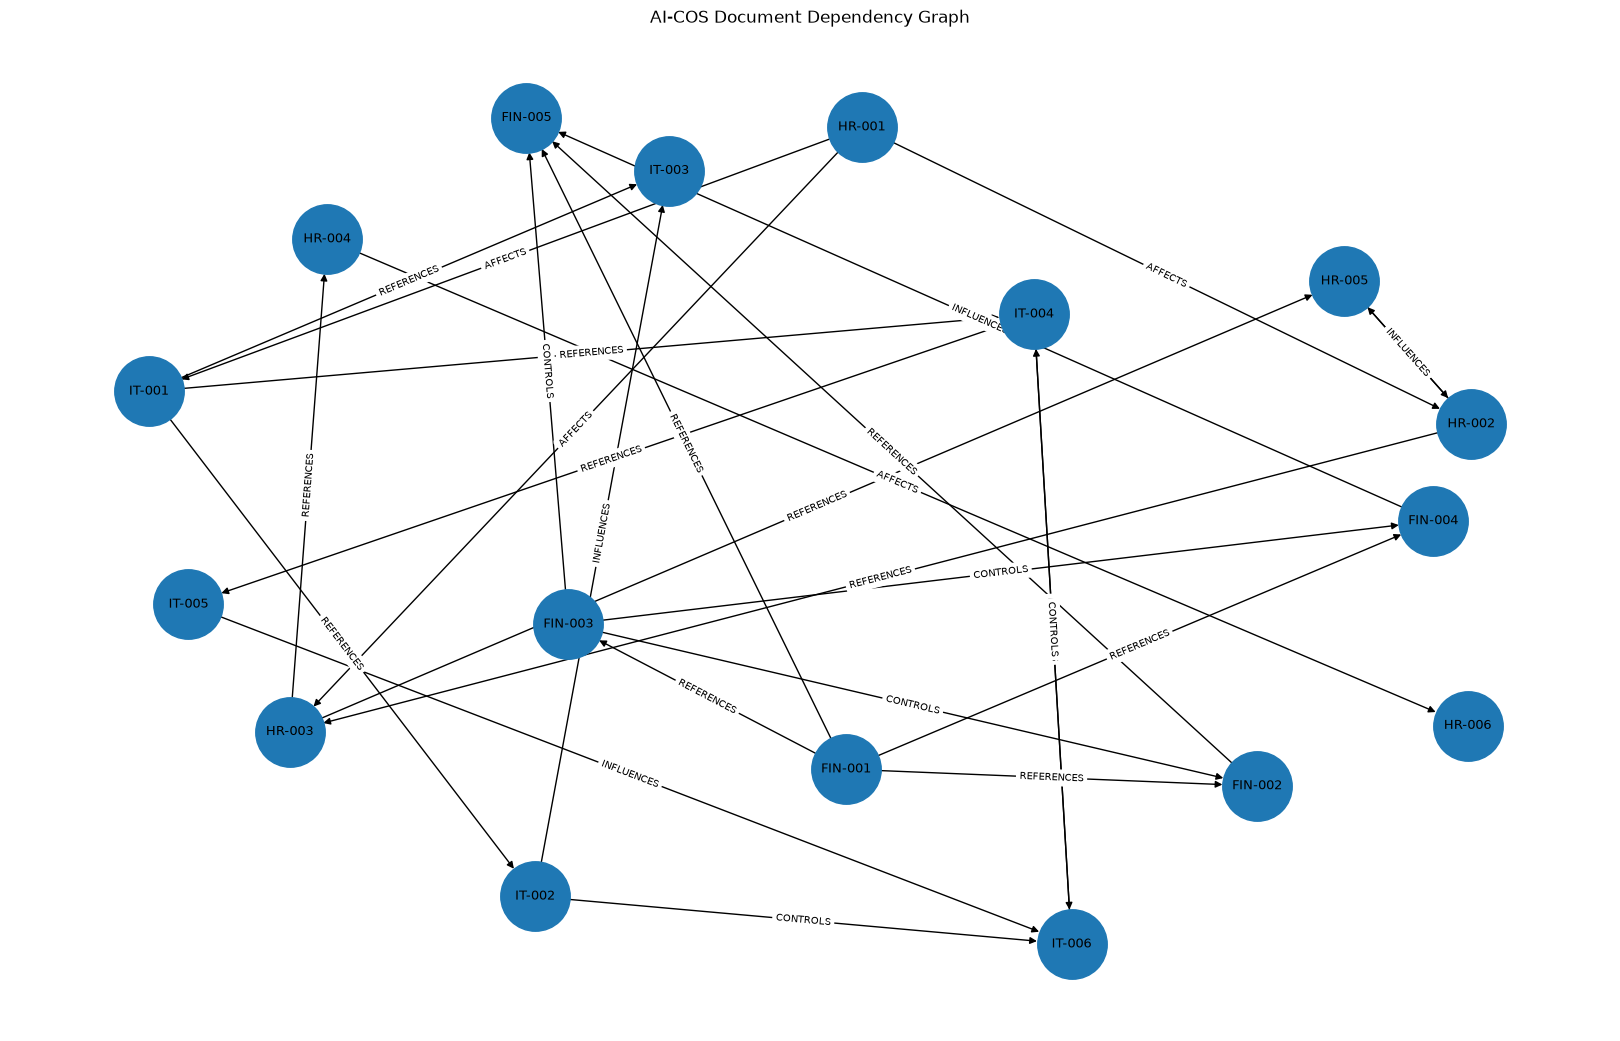

In [75]:
plt.figure(figsize=(16,10))

pos = nx.spring_layout(G,seed=42,k=2)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=2500,
    font_size=9,
    arrows=True
)

edge_labels = nx.get_edge_attributes(G,"relationship")

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=7
)

plt.title("AI-COS Document Dependency Graph")
plt.show()

In [76]:
def get_direct_dependencies(document_id):
    return list(G.successors(document_id))

In [77]:
print(get_direct_dependencies("HR-001"))

['HR-002', 'HR-003', 'IT-001']


In [78]:
def get_dependents(document_id):
    return list(G.predecessors(document_id))

In [79]:
print(get_dependents("IT-001"))

['HR-001']


In [81]:
affected = get_all_affected_documents("HR-001")

print("Affected documents:")
for doc in affected:
    print(doc)

Affected documents:
IT-006
IT-003
IT-005
HR-006
HR-002
IT-002
IT-004
HR-003
HR-004
HR-005
IT-001


In [82]:
def find_paths(source,target):
    try:
        return list(nx.all_simple_paths(G,source,target))
    except nx.NetworkXNoPath:
        return []

In [83]:
paths = find_paths("HR-001","IT-003")

for path in paths:
    print(" → ".join(path))

HR-001 → IT-001 → IT-002 → IT-003
HR-001 → IT-001 → IT-003
